# 05. 몬테카를로 시뮬레이션: 플로어 운용 정책 비교

**질문:** 발행사가 어떤 플로어 전략을 쓰면 **"3년 중 한 해라도 적자"일 확률을 5% 이하**로 지키면서 **헤지 비용을 가장 적게** 쓸 수 있나? 발행사 규모에 따라 답이 달라지나?

- **몬테카를로 시뮬레이션**: 미래 금리 경로를 무작위로 수천~수만 개 만들어, 각 경로에서 발행사 손익을 계산한 뒤 그 **분포**를 보는 방법.

**메인 설정 (CLAUDE.md "최종 범위")**

| 항목 | 설정 |
|---|---|
| 금리 | 시장 일치 모형 r(t) = f(0, t) + x(t), a = 0.093, σ = 0.64. 월간 36개월, 경로 10,000개 |
| 곡선 | 미국채 − 18bp(1개월 국채 − SOFR), PCHIP 보간 |
| 준비금 수익률 | max(r, 0) − 0.15%p (Circle 실제 수익률 검증 결과) |
| 발행사 손익 | 매달 (1 − s) × 준비금 수익률 × R ÷ 12 − C ÷ 12. C·s는 Circle 값 |
| 발행량 | **R 고정 (g = 0)**, b1 = 0. 최근 24개월 성장률(연 30%)은 비교용 |
| 규모 | r* 기준: 신규 진입 4.5%, Circle 수준 3.6%, 대형 2.5% → R 역산 |
| 플로어 | 명목 N = h × R. 정산: 매달 N × max(K − r, 0) ÷ 12. 가격: 바슐리에 + 등가 σ |
| 행사가 | 규모마다 r* − 1%, r* − 0.5%, r*, r* + 0.5% |
| 거래비용 | 연 2bp × N |
| 전략 | 무헤지 + K 4개 × h(1 − s = 37.5%, 50%, 100%) × 만기(1년 롤링, 3년) = 25개 |
| 평가 | **한 해라도 연간 적자인 경로 비율** = 손실확률, 총 헤지 비용(보험료·거래비용). 3년 누적 기준은 참고 |

## 1. 준비
이 셀이 하는 일: 도구와 함수를 불러오고 경로·그래프 설정을 한다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
from src.floor_pricing import build_curve, price_floor, price_floor_later, monthly_forwards
from src.rate_model import simulate_market_consistent
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. 입력값

### Circle 기준 고정비 C와 배분율 s
이 셀이 하는 일: 01번 노트북 3번 섹션에서 저장한 값을 읽는다.

In [2]:
circle = pd.read_csv(PROC_DIR / "circle_params.csv", index_col=0)["value"]
C = float(circle["C_musd_per_year"]) * 1e6      # 달러/년
S = float(circle["s"])                          # 배분율
YIELD_GAP = 0.15                                # 준비금 수익률 = max(r, 0) − 0.15%p
print(f"고정비 C = {C / 1e6:,.0f} 백만 달러/년 | 배분율 s = {S:.3f} → 발행사 몫 1 − s = {1 - S:.3f}")

고정비 C = 962 백만 달러/년 | 배분율 s = 0.625 → 발행사 몫 1 − s = 0.375


### 성장률
이 셀이 하는 일: 메인은 **g = 0**(발행량이 3년간 그대로)이다. 비교용으로 USDC 제외 시장의 최근 24개월 평균 성장률도 계산해 둔다.
- g = 0을 메인으로 하는 이유: 손실확률은 **성장이 멈췄을 때**도 버틸 수 있는지를 봐야 한다. 최근 24개월은 금리 인하기와 GENIUS법이 겹친 특수한 성장기였다.

In [3]:
monthly = pd.read_parquet(PROC_DIR / "usdc_rates_monthly.parquet").loc[:"2026-09-30"]
ex_usdc = monthly["stable_total_bn"] - monthly["usdc_bn"]
G_MAIN = 0.0
G_RECENT = np.log(ex_usdc).diff().iloc[-24:].mean()
print(f"메인 g = 0 | 비교용 최근 24개월 g = {G_RECENT:.4f}/월 (연 {np.exp(G_RECENT * 12) - 1:+.1%})")

메인 g = 0 | 비교용 최근 24개월 g = 0.0219/월 (연 +30.1%)


### 금리 곡선과 모형 파라미터
이 셀이 하는 일: 04번과 같은 방법으로 보정 곡선(−18bp, PCHIP)을 만들고, 분기 곡선(플로어 가격용)과 월별 선도금리(시뮬레이션용)를 준비한다.

In [4]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")
CURVE_IDS = ["DGS1MO", "DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS10"]
MATURITIES = np.array([1 / 12, 0.25, 0.5, 1, 2, 3, 5, 10])

curve_row = rates[CURVE_IDS].dropna().iloc[-1]
sofr_today = rates.loc[curve_row.name, "SOFR"]
SHIFT_BP = (curve_row["DGS1MO"] - sofr_today) * 100

A, SIGMA = 0.093, 0.64          # 03번 추정 (평균회귀 속도, 변동성)
MONTHS, N_PATHS = 36, 10_000

curve = build_curve(curve_row.values, MATURITIES, horizon=3.0, shift_bp=SHIFT_BP, method="pchip")
fwd = monthly_forwards(curve_row.values, MATURITIES, months=MONTHS, shift_bp=SHIFT_BP, method="pchip")
print(f"곡선 날짜 {curve_row.name:%Y-%m-%d} | 보정 {SHIFT_BP:.0f}bp | 첫 달 선도금리 {fwd[0]:.2f}% → 36개월째 {fwd[-1]:.2f}%")

곡선 날짜 2026-10-26 | 보정 18bp | 첫 달 선도금리 3.93% → 36개월째 4.69%

## 3. 발행사 3개 규모

고정비 C와 배분율 s는 Circle과 같고 **준비금 R만 다르게** 둔다. 손익분기 금리 r*가 목표값이 되도록 R을 거꾸로 계산한다.

$$r^* = \frac{C}{(1 - s)\,R} \quad\Rightarrow\quad R = \frac{C}{(1 - s)\,r^*}$$

- **r\* (손익분기 금리)**: 발행사 몫의 준비금 수익률이 이보다 낮으면 적자가 나는 수준.
- 준비금 수익률이 기준금리보다 0.15%p 낮으므로, **기준금리로 보면** 손익분기점은 r* + 0.15%p다.

| 규모 | r* | 의미 |
|---|---|---|
| 신규 진입 | 4.5% | 아직 작아서 고정비 부담이 큰 발행사. 지금 금리(3.93%)보다 높다 |
| Circle 수준 | 3.6% | 실제 Circle의 r* (01번 3번 섹션 값 기준) |
| 대형 | 2.5% | 규모가 커서 고정비 부담이 작은 발행사 |

이 셀이 하는 일: 세 규모의 R과 r*, 기준금리 기준 손익분기점, 그리고 규모별 행사가 4개를 표로 보여준다.

In [5]:
TARGET_RSTAR = {"신규 진입": 4.5, "Circle 수준": 3.6, "대형": 2.5}       # %
R0 = {size: C / ((1 - S) * rstar / 100) for size, rstar in TARGET_RSTAR.items()}
STRIKE_OFFSETS = [-1.0, -0.5, 0.0, 0.5]                                   # r* 기준 행사가 차이 (%p)
STRIKES = {size: [round(rstar + off, 2) for off in STRIKE_OFFSETS] for size, rstar in TARGET_RSTAR.items()}

usdc_now = pd.read_parquet(PROC_DIR / "usdc_rates.parquet")["usdc_bn"].iloc[-1] * 1e9
pd.DataFrame({
    "R (10억 달러)":              {k: v / 1e9 for k, v in R0.items()},
    "r* (%)":                    TARGET_RSTAR,
    "기준금리 기준 손익분기점 (%)":    {k: v + YIELD_GAP for k, v in TARGET_RSTAR.items()},
    "행사가 K (%)":                {k: ", ".join(f"{x:.1f}" for x in v) for k, v in STRIKES.items()},
}).assign(**{"참고: 실제 USDC (10억 달러)": [np.nan, usdc_now / 1e9, np.nan]})

,R (10억 달러),r* (%),기준금리 기준 손익분기점 (%),행사가 K (%),참고: 실제 USDC (10억 달러)
신규 진입,56.9957,4.5000,4.6500,"3.5, 4.0, 4.5, 5.0",NaN
Circle 수준,71.2447,3.6000,3.7500,"2.6, 3.1, 3.6, 4.1",71.7120
대형,102.5923,2.5000,2.6500,"1.5, 2.0, 2.5, 3.0",NaN


## 4. 금리 경로

이 셀이 하는 일: 시장 일치 모형으로 36개월 금리 경로 10,000개를 만든다. 경로 평균 = 선도금리가 되도록 만든 모형이다.

In [6]:
paths = simulate_market_consistent(fwd, A, SIGMA, n_paths=N_PATHS, seed=42)   # (10000, 37): 0~36개월
r = paths[:, :MONTHS]                                                          # 0~35개월: 매달 적용 금리
x_state = paths - fwd[np.newaxis, :]                                           # 경로별 충격 x(t)

pd.DataFrame({
    "5%":    np.percentile(paths, 5, axis=0),
    "중앙값":  np.median(paths, axis=0),
    "95%":   np.percentile(paths, 95, axis=0),
    "선도금리": fwd,
}).iloc[[0, 12, 24, 36]].rename(index=lambda m: f"{m}개월")

,5%,중앙값,95%,선도금리
0개월,3.9300,3.9300,3.9300,3.9300
12개월,3.4987,4.4847,5.5045,4.4950
24개월,3.4186,4.7453,6.1166,4.7528
36개월,3.1077,4.6924,6.2970,4.6939


### 금리 분포와 세 규모의 손익분기점
이 셀이 하는 일: 경로의 5~95% 범위와 중앙값을 그리고, 세 규모의 **기준금리 기준 손익분기점**(r* + 0.15%p)을 가로선으로 겹쳐 그린다. 금리가 선 아래로 내려가는 달에는 그 규모의 발행사가 그 달 적자다.

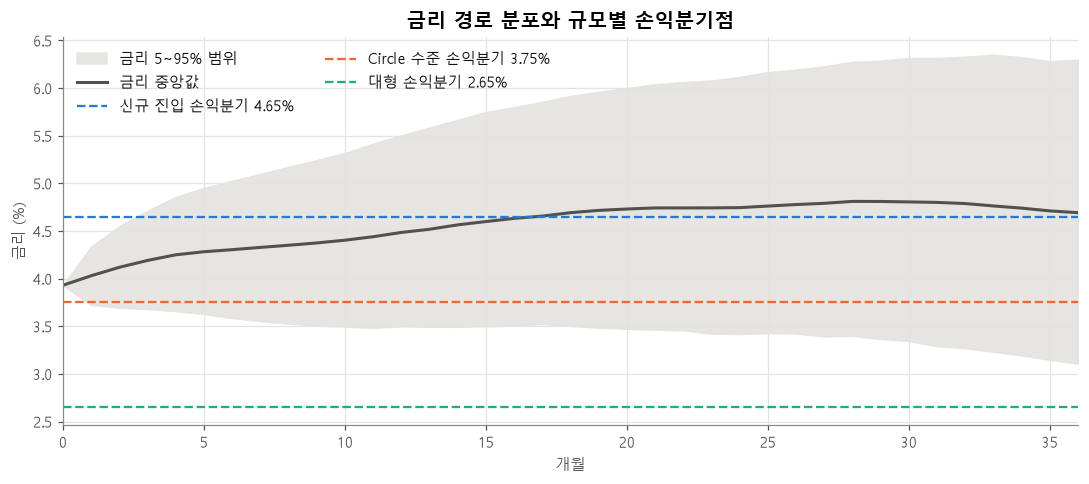

In [7]:
months_axis = np.arange(MONTHS + 1)
p5, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(months_axis, p5, p95, color=SHADE, alpha=0.9, label="금리 5~95% 범위")
ax.plot(months_axis, p50, color=TEXT_SUB, linewidth=2, label="금리 중앙값")
for (size, rstar), color in zip(TARGET_RSTAR.items(), COLORS):
    ax.axhline(rstar + YIELD_GAP, color=color, linestyle="--", label=f"{size} 손익분기 {rstar + YIELD_GAP:.2f}%")

ax.set_xlim(0, MONTHS)
ax.set_title("금리 경로 분포와 규모별 손익분기점")
ax.set_xlabel("개월")
ax.set_ylabel("금리 (%)")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "6_rates_vs_rstar.png", dpi=200)
plt.show()

## 5. 발행사 연간 손익 (무헤지)

$$\pi_{\text{월}} = (1 - s)\,\big(\max(r, 0) - 0.15\big)\,\frac{R}{12} - \frac{C}{12}$$

- 1년차 = 0~11개월, 2년차 = 12~23개월, 3년차 = 24~35개월의 월 손익을 더한 값.
- **손실확률(메인)**: 세 해 중 **한 해라도** 연간 손익이 0보다 작은 경로의 비율. 3년을 합치면 초반 이익이 뒤의 손실을 덮어 위험이 작게 보이기 때문이다.
- **참고**: 3년 누적 손익(할인 없이 합산)이 0보다 작은 경로의 비율.

이 셀이 하는 일: 경로별 월 손익을 연 단위로 묶는 함수와, 규모별 무헤지 결과를 만든다.

In [8]:
k = np.arange(MONTHS)                     # 0~35개월
YEAR_OF_MONTH = k // 12                   # 0, 1, 2년차


def to_years(monthly_cash):
    # (경로, 36개월) → (경로, 3년) 연간 합계
    return np.stack([monthly_cash[:, YEAR_OF_MONTH == y].sum(axis=1) for y in range(3)], axis=1)


def base_annual(R_start, g=G_MAIN):
    # 무헤지 연간 손익 (경로, 3년), 달러
    R_t = R_start * np.exp(g * k)
    reserve_yield = np.maximum(r, 0) - YIELD_GAP               # %
    income = (1 - S) * reserve_yield / 100 * R_t / 12
    return to_years(income - C / 12)


def loss_probs(annual):
    # (한 해라도 적자 확률, 3년 누적 적자 확률) — %
    return (annual < 0).any(axis=1).mean() * 100, (annual.sum(axis=1) < 0).mean() * 100

base = {size: base_annual(R_start) for size, R_start in R0.items()}
pd.DataFrame({
    "평균 연간 손익 (백만 달러)":     {s_: v.mean() / 1e6 for s_, v in base.items()},
    "한 해라도 적자 (%)":          {s_: loss_probs(v)[0] for s_, v in base.items()},
    "참고: 3년 누적 적자 (%)":      {s_: loss_probs(v)[1] for s_, v in base.items()},
})

,평균 연간 손익 (백만 달러),한 해라도 적자 (%),참고: 3년 누적 적자 (%)
신규 진입,-18.2753,90.1900,56.5100
Circle 수준,217.5454,16.5300,7.2100
대형,736.3509,0.7900,0.0200


## 6. 플로어

- **정산**: 매달 N × max(K − r, 0) ÷ 12. 금리가 K 아래인 달에 그 차이만큼 받는다.
- **거래비용**: 매년 N × 2bp.
- **보험료**:
  - **3년 만기**: 처음에 3년짜리를 한 번 산다. 가격은 지금 곡선으로 정해져 모든 경로에서 같다.
  - **1년 롤링**: 0, 12, 24개월에 1년짜리를 새로 산다. 12·24개월에는 **그때의 금리 상태**로 가격이 정해지므로 경로마다 다르다. (그때 선도금리 ≈ 지금 선도금리 + x(t)·e^(−a(T − t)))
- **연간 손익에 보험료를 나누는 방법**: 보험료는 보호받는 기간에 고르게 나눠 비용으로 잡는다. 3년 만기는 매년 1/3씩, 1년 롤링은 산 해에 전부. (회계에서 보험료를 기간에 나눠 비용 처리하는 것과 같다. 3년 만기 보험료를 1년차에 다 넣으면 1년차만 불리해진다)

이 셀이 하는 일: 한 전략의 경로별 연간 (보험료, 거래비용, 정산액)을 계산하는 함수를 만든다.

In [9]:
TC_BP_PER_YEAR = 2.0


def floor_annual(R_start, K, h, tenor):
    # 반환: 보험료(경로, 3년), 거래비용(3년), 정산액(경로, 3년) — 달러
    N = h * R_start
    payoff = to_years(N * np.maximum(K - r, 0) / 100 / 12)
    tcost = np.full(3, N * TC_BP_PER_YEAR / 10_000)
    if tenor == "3년":
        total = price_floor(curve, K, 3, SIGMA, a=A)[0]["floor"] * N / 100
        premium = np.full((N_PATHS, 3), total / 3)                 # 3년에 고르게 나눔
    else:   # 1년 롤링: 0, 12, 24개월에 1년짜리 매입
        premium = np.stack([price_floor_later(curve, year, x_state[:, 12 * year], K, 1, SIGMA, A) * N / 100
                            for year in range(3)], axis=1)
    return premium, tcost, payoff

### 25개 전략 정의
이 셀이 하는 일: 규모마다 무헤지 + K 4개 × h 3개 × 만기 2개 = 25개 전략 목록을 만든다. 전략 이름에는 r* 대비 행사가 위치를 적는다.
- 헤지 비율 h 후보: **1 − s(≈ 37.5%, 발행사 몫)**, 50%, 100%

In [10]:
HEDGE_RATIOS = [round(1 - S, 3), 0.5, 1.0]   # 1 − s ≈ 0.375 (발행사 몫), 50%, 100%
TENORS = ["1년 롤링", "3년"]


def strategies_for(size):
    rstar = TARGET_RSTAR[size]
    items = [("무헤지", None, None, None, None)]
    for off, K in zip(STRIKE_OFFSETS, STRIKES[size]):
        for h in HEDGE_RATIOS:
            for tenor in TENORS:
                items.append((f"K r*{off:+.1f} ({K:.1f}%) h{h * 100:g} {tenor}", K, off, h, tenor))
    return items

print(len(strategies_for("대형")), "개 전략 (예: 대형)")

25 개 전략 (예: 대형)


## 7. 시뮬레이션 실행
이 셀이 하는 일: 규모 3개 × 전략 25개 = 75개 조합마다 경로 1만 개의 연간 손익을 계산하고 결과를 표로 모은다. 비교용 성장률(연 30%)로도 같은 계산을 해 둔다.

$$\text{연간 손익} = \text{무헤지 연간 손익} + \text{플로어 정산액} - \text{보험료(나눈 몫)} - \text{거래비용}$$

In [11]:
def run_all(g):
    records = []
    for size, R_start in R0.items():
        base_y = base_annual(R_start, g=g)
        for name, K, off, h, tenor in strategies_for(size):
            if K is None:
                premium, tcost, payoff = np.zeros((N_PATHS, 3)), np.zeros(3), np.zeros((N_PATHS, 3))
            else:
                premium, tcost, payoff = floor_annual(R_start, K, h, tenor)
            annual = base_y + payoff - premium - tcost
            any_year, cumulative = loss_probs(annual)
            records.append({
                "규모": size, "전략": name, "K": K, "K−r*": off, "h": h, "만기": tenor,
                "손실확률(%)":          any_year,
                "참고: 3년 누적(%)":     cumulative,
                "보험료(백만$)":         premium.sum(axis=1).mean() / 1e6,
                "거래비용(백만$)":        tcost.sum() / 1e6,
                "총 헤지 비용(백만$)":     (premium.sum(axis=1).mean() + tcost.sum()) / 1e6,
                "평균 정산액(백만$)":      payoff.sum(axis=1).mean() / 1e6,
            })
    return pd.DataFrame(records)

results = run_all(G_MAIN)
results_g30 = run_all(G_RECENT)
print("계산한 조합:", len(results), "(메인) +", len(results_g30), "(비교용 g)")

계산한 조합: 75 (메인) + 75 (비교용 g)


## 8. 평가

### 규모별 결과표
이 셀이 하는 일: 규모마다 25개 전략의 손실확률과 비용(보험료·거래비용 나눠서)을 보여준다.

In [12]:
SHOW = ["전략", "손실확률(%)", "참고: 3년 누적(%)", "보험료(백만$)", "거래비용(백만$)", "총 헤지 비용(백만$)", "평균 정산액(백만$)"]
for size in R0:
    print(f"■ {size}  (R = {R0[size] / 1e9:.1f}bn 달러, r* {TARGET_RSTAR[size]}%)")
    print(results.loc[results["규모"] == size, SHOW].to_string(index=False, float_format=lambda v: f"{v:,.2f}"), end="\n\n")

■ 신규 진입  (R = 57.0bn 달러, r* 4.5%)
                         전략  손실확률(%)  참고: 3년 누적(%)  보험료(백만$)  거래비용(백만$)  총 헤지 비용(백만$)  평균 정산액(백만$)
                        무헤지    90.19         56.51      0.00       0.00          0.00         0.00
K r*-1.0 (3.5%) h37.5 1년 롤링    91.41         57.98     10.43      12.82         23.26        11.02
   K r*-1.0 (3.5%) h37.5 3년    91.73         58.81      9.73      12.82         22.56        11.02
  K r*-1.0 (3.5%) h50 1년 롤링    91.67         58.49     13.91      17.10         31.01        14.69
     K r*-1.0 (3.5%) h50 3년    92.21         59.60     12.98      17.10         30.08        14.69
 K r*-1.0 (3.5%) h100 1년 롤링    92.92         60.38     27.82      34.20         62.02        29.38
    K r*-1.0 (3.5%) h100 3년    93.98         62.69     25.96      34.20         60.15        29.38
K r*-0.5 (4.0%) h37.5 1년 롤링    92.96         59.05     45.55      12.82         58.37        48.03
   K r*-0.5 (4.0%) h37.5 3년    93.41         61.67     43.19      12.82    

### 효율적 투자선
- **효율적인 전략**: 다른 어떤 전략과 비교해도 "비용도 더 들고 손실확률도 더 높은" 경우가 아닌 전략.
- **비효율 전략**: 비용과 손실확률이 모두 같거나 나쁘고, 하나는 확실히 나쁜 다른 전략이 있는 전략. 고를 이유가 없다.

이 셀이 하는 일: 규모마다 비효율 전략을 표시하고, x축 = 총 헤지 비용, y축 = 손실확률로 그린다. 세 그래프는 **같은 축 범위**로 나란히 둔다. 5% 기준선과 최적 정책(★)도 표시한다.

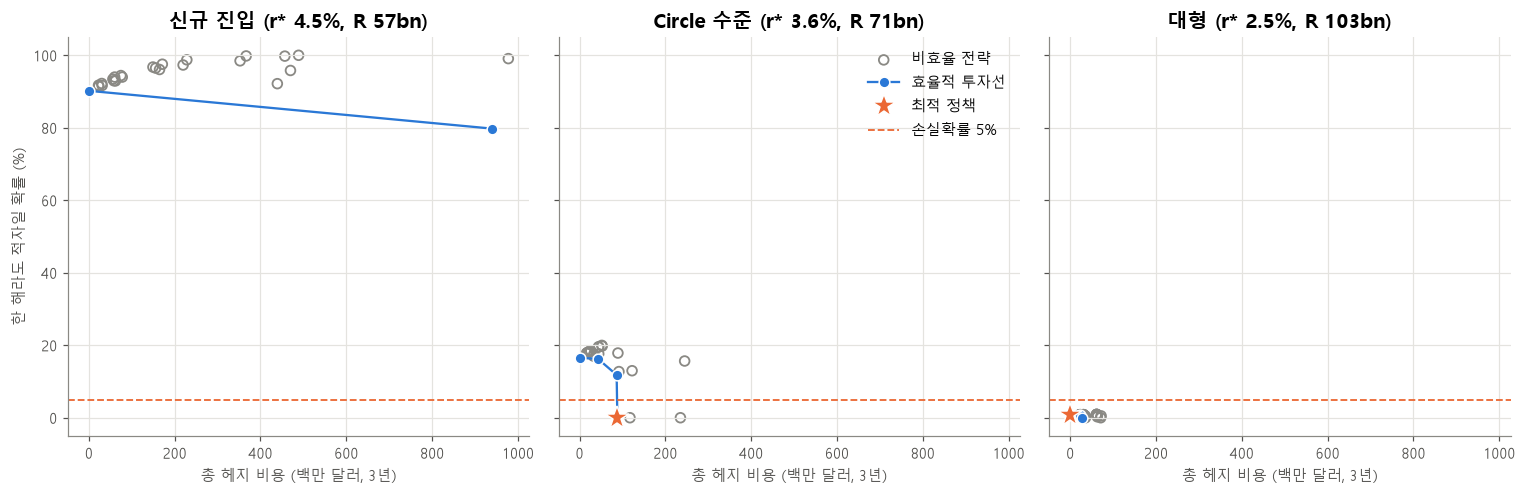

In [13]:
def mark_efficient(df):
    cost, loss = df["총 헤지 비용(백만$)"].to_numpy(), df["손실확률(%)"].to_numpy()
    return np.array([not ((cost <= cost[i]) & (loss <= loss[i]) & ((cost < cost[i]) | (loss < loss[i]))).any()
                     for i in range(len(df))])


def pick_optimal(df):
    ok = df[df["손실확률(%)"] <= 5]
    return ok.sort_values(["총 헤지 비용(백만$)", "손실확률(%)"]).iloc[0] if len(ok) else None

results["효율적"] = False
for size in R0:
    idx = results["규모"] == size
    results.loc[idx, "효율적"] = mark_efficient(results[idx])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, size in zip(axes, R0):
    sub = results[results["규모"] == size]
    eff, ineff = sub[sub["효율적"]].sort_values("총 헤지 비용(백만$)"), sub[~sub["효율적"]]
    ax.scatter(ineff["총 헤지 비용(백만$)"], ineff["손실확률(%)"], s=40, facecolor="none",
               edgecolor=MUTED, linewidth=1.2, label="비효율 전략")
    ax.plot(eff["총 헤지 비용(백만$)"], eff["손실확률(%)"], color=COLORS[0], marker="o",
            markersize=7, markeredgecolor="white", label="효율적 투자선")
    best = pick_optimal(sub)
    if best is not None:
        ax.plot(best["총 헤지 비용(백만$)"], best["손실확률(%)"], marker="*", markersize=16,
                color=COLORS[1], markeredgecolor="white", linestyle="none", label="최적 정책")
    ax.axhline(5, color=COLORS[1], linestyle="--", linewidth=1.2, label="손실확률 5%")
    ax.set_title(f"{size} (r* {TARGET_RSTAR[size]}%, R {R0[size] / 1e9:.0f}bn)")
    ax.set_xlabel("총 헤지 비용 (백만 달러, 3년)")
axes[0].set_ylabel("한 해라도 적자일 확률 (%)")
axes[1].legend(loc="upper right")   # 네 가지 표시가 모두 있는 그래프에 범례
fig.tight_layout()
fig.savefig(FIG_DIR / "6_efficient_frontier.png", dpi=200)
plt.show()

### 규모별 최적 정책
이 셀이 하는 일: 규모마다 무헤지 손실확률과, **손실확률 5% 이하 중 총 헤지 비용이 가장 작은 전략**(최적 정책)을 표로 정리한다. 5% 이하 전략이 없으면 "없음"이라고 쓰고, 참고로 손실확률이 가장 낮은 전략을 함께 보여준다.

In [14]:
def optimal_table(res):
    rows = {}
    for size in R0:
        sub = res[res["규모"] == size]
        unhedged = sub.loc[sub["전략"] == "무헤지", "손실확률(%)"].iloc[0]
        best = pick_optimal(sub)
        lowest = sub.sort_values(["손실확률(%)", "총 헤지 비용(백만$)"]).iloc[0]
        pick = best if best is not None else lowest
        rows[size] = {
            "무헤지 손실확률(%)": unhedged,
            "최적 전략":         best["전략"] if best is not None else f"없음 (최저: {lowest['전략']})",
            "손실확률(%)":       pick["손실확률(%)"],
            "보험료(백만$)":      pick["보험료(백만$)"],
            "거래비용(백만$)":     pick["거래비용(백만$)"],
            "총 비용(백만$)":     pick["총 헤지 비용(백만$)"],
            "총 비용(R 대비 bp/년)": pick["총 헤지 비용(백만$)"] * 1e6 / R0[size] / 3 * 10_000,
        }
    return pd.DataFrame(rows).T

optimal = optimal_table(results)
optimal

,무헤지 손실확률(%),최적 전략,손실확률(%),보험료(백만$),거래비용(백만$),총 비용(백만$),총 비용(R 대비 bp/년)
신규 진입,90.1900,없음 (최저: K r*+0.5 (5.0%) h100 3년),79.7600,905.5887,34.1974,939.7862,54.9624
Circle 수준,16.5300,K r*+0.5 (4.1%) h37.5 3년,0.0000,72.1710,16.0301,88.2010,4.1267
대형,0.7900,무헤지,0.7900,0.0000,0.0000,0.0000,0.0000


### 1년 롤링 vs 3년 만기
이 셀이 하는 일: 같은 K·h에서 두 만기의 손실확률과 비용을 나란히 비교한다.

In [15]:
hedged = results[results["K"].notna()]
tenor_compare = hedged.pivot_table(index=["규모", "K−r*", "h"], columns="만기",
                                   values=["손실확률(%)", "보험료(백만$)", "총 헤지 비용(백만$)"])
tenor_compare = tenor_compare.reindex(columns=["1년 롤링", "3년"], level=1).reindex(list(R0), level=0)
tenor_compare.round(2)

보험료(백만$)          손실확률(%)         총 헤지 비용(백만$)  \
만기                          1년 롤링       3년   1년 롤링      3년        1년 롤링   
규모        K−r*    h                                                       
신규 진입     -1.0000 0.3750  10.4300   9.7300 91.4100 91.7300      23.2600   
                  0.5000  13.9100  12.9800 91.6700 92.2100      31.0100   
                  1.0000  27.8200  25.9600 92.9200 93.9800      62.0200   
          -0.5000 0.3750  45.5500  43.1900 92.9600 93.4100      58.3700   
                  0.5000  60.7300  57.5900 93.9800 94.4000      77.8300   
                  1.0000 121.4700 115.1900 96.4600 96.7500     155.6600   
          0.0000  0.3750 158.4500 151.9100 97.5300 96.0700     171.2700   
                  0.5000 211.2700 202.5500 98.7400 97.3100     228.3700   
                  1.0000 422.5300 405.1000 99.7600 92.1600     456.7300   
          0.5000  0.3750 353.7700 339.6000 99.8100 98.4600     366.5900   
                  0.5000 471.6900 452.7900 99.9900 95.8000     488.7900   
                  1.0000 943.3800 905.5900 99.0700 79.7600     977.5800   
Circle 수준 -1.0000 0.3750   0.7000   0.6300 17.7800 17.8200      16.7300   
                  0.5000   0.9300   0.8500 18.1900 18.2100      22.3000   
                  1.0000   1.8600   1.6900 19.5200 19.5600      44.6100   
          -0.5000 0.3750   3.7800   3.4800 18.0200 18.0300      19.8100   
                  0.5000   5.0500   4.6400 18.3900 18.4500      26.4200   
                  1.0000  10.0900   9.2700 19.7800 19.9600      52.8400   
          0.0000  0.3750  17.5500  16.4300 17.5000 17.0200      33.5800   
                  0.5000  23.4000  21.9000 17.6300 16.2300      44.7700   
                  1.0000  46.8000  43.8100 17.8500 11.8100      89.5500   
          0.5000  0.3750  75.8500  72.1700 12.7300  0.0000      91.8800   
                  0.5000 101.1400  96.2300 12.9700  0.0000     122.5100   
                  1.0000 202.2700 192.4600 15.6500  0.0000     245.0200   
대형        -1.0000 0.3750   0.0100   0.0100  0.8400  0.8400      23.1000   
                  0.5000   0.0200   0.0200  0.8400  0.8400      30.7900   
                  1.0000   0.0300   0.0300  0.9000  0.9000      61.5900   
          -0.5000 0.3750   0.1100   0.0900  0.8400  0.8400      23.1900   
                  0.5000   0.1400   0.1300  0.8500  0.8400      30.9200   
                  1.0000   0.2800   0.2500  0.9200  0.9000      61.8400   
          0.0000  0.3750   0.7000   0.6400  0.8100  0.7200      23.7900   
                  0.5000   0.9400   0.8500  0.7700  0.6100      31.7100   
                  1.0000   1.8700   1.7000  0.6600  0.2600      63.4300   
          0.5000  0.3750   3.9400   3.6100  0.5000  0.0000      27.0200   
                  0.5000   5.2500   4.8100  0.4300  0.0000      36.0300   
                  1.0000  10.5100   9.6200  0.5100  0.0000      72.0600   

                                   
만기                             3년  
규모        K−r*    h                
신규 진입     -1.0000 0.3750  22.5600  
                  0.5000  30.0800  
                  1.0000  60.1500  
          -0.5000 0.3750  56.0200  
                  0.5000  74.6900  
                  1.0000 149.3800  
          0.0000  0.3750 164.7400  
                  0.5000 219.6500  
                  1.0000 439.3000  
          0.5000  0.3750 352.4200  
                  0.5000 469.8900  
                  1.0000 939.7900  
Circle 수준 -1.0000 0.3750  16.6600  
                  0.5000  22.2200  
                  1.0000  44.4400  
          -0.5000 0.3750  19.5100  
                  0.5000  26.0100  
                  1.0000  52.0200  
          0.0000  0.3750  32.4600  
                  0.5000  43.2800  
                  1.0000  86.5500  
          0.5000  0.3750  88.2000  
                  0.5000 117.6000  
                  1.0000 235.2000  
대형        -1.0000 0.3750  23.0900  
                  0.5000  30.7900  
                  1.0000  61.5900  
          -0.5000 0

### 점검: 해마다의 적자확률과 보험료 배분 방식
1년 롤링과 3년 만기의 차이가 어디서 나오는지 보기 위해, Circle 수준에서 몇 가지 전략의 **해별 적자확률**을 본다. 3년 만기 보험료를 고르게 나누지 않고 **1년차에 전부** 비용으로 잡았을 때도 계산한다(배분 가정에 결론이 좌우되는지 확인).

이 셀이 하는 일: Circle 수준에서 무헤지와 세 전략의 1·2·3년차 적자확률, 그리고 한 해라도 적자일 확률을 표로 만든다.

In [16]:
R_circle = R0["Circle 수준"]
base_circle = base_annual(R_circle)
check_rows = {"무헤지": base_circle}
for K, h in [(4.1, round(1 - S, 3)), (4.1, 0.5), (3.6, 1.0)]:
    for tenor in TENORS:
        premium, tcost, payoff = floor_annual(R_circle, K, h, tenor)
        check_rows[f"K {K}% h{h * 100:g} {tenor}"] = base_circle + payoff - premium - tcost
        if tenor == "3년":   # 보험료를 1년차에 전부
            upfront = np.zeros_like(premium)
            upfront[:, 0] = premium.sum(axis=1)
            check_rows[f"K {K}% h{h * 100:g} 3년 (보험료 1년차에 전부)"] = base_circle + payoff - upfront - tcost

pd.DataFrame({name: {"1년차 적자(%)": (a[:, 0] < 0).mean() * 100, "2년차 적자(%)": (a[:, 1] < 0).mean() * 100,
                     "3년차 적자(%)": (a[:, 2] < 0).mean() * 100, "한 해라도 적자(%)": (a < 0).any(axis=1).mean() * 100}
              for name, a in check_rows.items()}).T.round(2)

,1년차 적자(%),2년차 적자(%),3년차 적자(%),한 해라도 적자(%)
무헤지,6.1400,8.7300,11.0600,16.5300
K 4.1% h37.5 1년 롤링,0.0000,6.5300,9.8100,12.7300
K 4.1% h37.5 3년,0.0000,0.0000,0.0000,0.0000
K 4.1% h37.5 3년 (보험료 1년차에 전부),0.0000,0.0000,0.0000,0.0000
K 4.1% h50 1년 롤링,0.0000,6.4000,9.4800,12.9700
K 4.1% h50 3년,0.0000,0.0000,0.0000,0.0000
K 4.1% h50 3년 (보험료 1년차에 전부),0.1300,0.0000,0.0000,0.1300
K 3.6% h100 1년 롤링,3.5400,9.0200,11.2400,17.8500
K 3.6% h100 3년,5.9600,4.0300,3.7500,11.8100
K 3.6% h100 3년 (보험료 1년차에 전부),16.6100,1.9300,1.8600,18.5600


**읽는 법**
- 무헤지는 해가 갈수록 적자확률이 커진다(약 6% → 9% → 11%). 시간이 지날수록 금리가 더 넓게 퍼지기 때문이다.
- **1년 롤링**은 1년차는 막지만 **2·3년차 적자가 남는다.** 금리가 이미 내려간 뒤 다시 사면, 그만큼 보험료가 올라 보호 효과를 상쇄한다. 불이 난 뒤에 화재보험을 새로 드는 것과 같다.
- **3년 만기**는 지금 가격으로 3년 보호를 **고정**한다. 보험료를 1년차에 전부 잡아도 K 4.1%·h 50%는 한 해라도 적자 확률이 약 0.1%로 5% 기준을 통과한다. 결론이 배분 가정에 좌우되지 않는다.

### 비교: 성장률 연 30%(최근 24개월)라면
이 셀이 하는 일: 같은 계산을 최근 24개월 성장률로 한 결과를 한 줄로 요약한다.

In [17]:
opt_g30 = optimal_table(results_g30)
print("g 연 30%: " + " | ".join(
    f"{size} 무헤지 {row['무헤지 손실확률(%)']:.1f}% → 최적 {row['최적 전략']}" for size, row in opt_g30.iterrows()))

g 연 30%: 신규 진입 무헤지 34.8% → 최적 K r*+0.0 (4.5%) h37.5 3년 | Circle 수준 무헤지 0.5% → 최적 무헤지 | 대형 무헤지 0.0% → 최적 무헤지


**읽는 법**
- **신규 진입 (r* 4.5%)**: 무헤지 손실확률이 약 **90%**다. 기준금리 기준 손익분기점(4.65%)이 1년차 선도금리(3.9~4.4%)보다 높아서, 적자가 "드문 위험"이 아니라 **예상되는 결과**다. 플로어는 공정한 가격의 보험이라 평균 손익을 올려 주지 못한다(평균 정산액 ≈ 보험료). 그래서 어떤 전략으로도 5%에 닿지 못한다. 가장 낮은 K 5.0%·h 100%·3년도 약 80%이고, 비용은 R의 연 약 55bp다.
- **Circle 수준 (r* 3.6%)**: 무헤지 약 **16.5%**로 5% 기준을 넘는다. **최적 정책은 K 4.1%(r* + 0.5)·h 50%·3년 만기**로, 손실확률 0%, 비용은 약 1.2억 달러(보험료 약 0.96억 + 거래비용 약 0.21억)다. R 대비 연 약 5.5bp다.
  - **h 50%로 충분한 이유**: 발행사는 준비금 이자의 37.5%(1 − s)만 가진다. 금리가 1%p 내리면 손실은 R × 0.375 × 1%이고, h 50% 플로어의 정산은 R × 0.5 × 1%라 손실보다 크다. h 100%는 **과잉 헤지**라 비용만 두 배다.
  - **K가 r* 이하이면 부족하다**: 기준금리 기준 손익분기점이 r* + 0.15%p(3.75%)라서, K 3.6% 이하 플로어는 금리가 3.6~3.75%일 때의 적자를 막지 못한다(K 3.6%·h 100%·3년도 약 12%).
- **대형 (r* 2.5%)**: 무헤지 약 0.8%로 이미 기준을 통과한다. 최적 정책은 무헤지다.
- **1년 롤링 vs 3년 만기**: 같은 K·h라도 3년 만기가 손실확률을 훨씬 크게 낮춘다(Circle 수준 K 4.1%·h 50%: 롤링 약 13% vs 3년 0%). 보험료도 3년 만기가 약 5~10% 싸다.
- **성장률 연 30%라면**: 신규 진입도 무헤지 약 35% → K 4.5%·h 50%·3년으로 5% 달성이 가능하고, Circle 수준·대형은 무헤지로 충분하다. 성장이 계속된다는 가정이 결론을 크게 바꾼다.

## 9. 결과 요약

| 규모 | R | 무헤지 손실확률 | 최적 정책 | 손실확률 | 비용 (보험료 + 거래비용) |
|---|---|---|---|---|---|
| 신규 진입 (r* 4.5%) | 570억 달러 | 약 90% | **없음** (최저: K 5.0%·h 100%·3년, 약 80%) | — | — |
| Circle 수준 (r* 3.6%) | 712억 달러 | 약 16.5% | **K 4.1%·h 50%·3년** | 0% | 약 1.18억 달러 (0.96 + 0.21), R의 연 5.5bp |
| 대형 (r* 2.5%) | 1,026억 달러 | 약 0.8% | 무헤지 | 0.8% | 0 |

**핵심 메시지 판단**
- **메시지 3 (플로어 최적 운용)**: **드러난다.** Circle 수준에서 무헤지는 5% 기준을 넘고, 효율적 투자선 위에서 "r*보다 약간 높은 K, 발행사 몫(1 − s)에 맞춘 h 50%, 3년 만기"가 R의 연 약 5.5bp로 기준을 맞춘다.
- **메시지 4 (만기 선택, 작은 발행사)**: **부분적으로 드러난다.** 만기 선택은 결정적이다(같은 K·h에서 롤링 13% vs 3년 0%). 작은 발행사일수록 필요한 비용이 커지는 것도 맞다(대형 0 → Circle 연 5.5bp → 신규 진입 연 55bp 이상). 다만 신규 진입은 "비싸다"를 넘어 **플로어로는 해결이 안 된다.** 손익분기점이 선도금리보다 높으면 공정한 가격의 보험은 평균 적자를 메워 주지 못한다. 또 "지금 플로어가 싸다"는 낮은 K에만 해당하고, 실제로 필요한 K(손익분기 근처)는 싸지 않다.